# Auto-detect open-sea direction sectors for each WHACS goal

For each goal, follow the AoI boundary and build the incoming-wave sector as
the outward half-plane of the local segment, **widened or narrowed by the
turn angles of the two adjacent vertices** so the opening adapts to the
local polygon shape:

* straight stretch → ~180° opening
* convex bends (polygon corners pointing inland) → > 180°
* concave bends (re-entrant corners) → < 180°

Plus a user-controlled margin on each side.

1. Load the user-curated goals from `inputs/WHACS/NorthCarolina_whacs.gpkg`
   (+ AoI + land for plotting), and **sort them by latitude desc, then longitude desc**.
2. Extract the AoI exterior ring (UTM 18N).
3. For each goal:
   - Snap onto the ring; identify the containing segment.
   - Compute the outward normal of that segment → sector centre.
   - Read the pre-computed CCW turn angles at the two endpoint vertices.
   - `opening = 180° + ½(turn_a + turn_b)` (signed; convex turn is positive).
   - Sector `[low, high] = [center − opening/2 − margin, center + opening/2 + margin]` in math degrees (CCW from East).
4. The math convention matches what `utils/simulations.py` expects today (it applies `(90 - wd) % 360` to convert to nautical *from* directions when sampling).
5. Plot every goal with its sector wedge.
6. Save:
   - the goals back to `inputs/WHACS/NorthCarolina_whacs.gpkg` with new attribute columns,
   - a JSON snippet ready to paste into the `goals` section of `NorthCarolina.json`.

In [1]:
import json

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Wedge
from shapely.geometry import Point
from utils.config import CASE_DIR, PATHS, resolve

## Parameters

In [2]:
# Sector geometry
sector_margin_deg = 5.0  # extra degrees added on each side of the natural opening

# Projected CRS used to do the geometry (meters). UTM zone 18N covers North Carolina.
work_crs = "EPSG:32618"
geo_crs = "EPSG:4326"

# Inputs / outputs
goals_path = resolve("inputs/WHACS/NorthCarolina_whacs.gpkg")
land_path = resolve("assets/eeuu.shp")  # only used for plotting
aoi_path = resolve(PATHS["aoi_file"])
goals_out_path = goals_path  # overwrite in place
json_out_path = resolve("outputs/goals_snippet.json")  # paste into NorthCarolina.json

print(f"goals  : {goals_path}")
print(f"AoI    : {aoi_path}")
print(f"land   : {land_path}  (used only for the plot)")
print(
    f"per-side margin = {sector_margin_deg:g}°  (opening = 180° + ½(turn_a + turn_b) + 2·margin)"
)

goals  : /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/inputs/WHACS/NorthCarolina_whacs.gpkg
AoI    : /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/inputs/AoI_Polygons/AoI_NorthCarolina.shp
land   : /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/assets/eeuu.shp  (used only for the plot)
per-side margin = 5°  (opening = 180° + ½(turn_a + turn_b) + 2·margin)


## Load goals, AoI, land

In [3]:
goals_gdf = gpd.read_file(goals_path).to_crs(geo_crs)
# Sort by latitude descending, then longitude descending, so goals are listed
# from NE to SW along the coast (matches the numbering of the existing JSON).
goals_gdf = goals_gdf.sort_values(
    ["latitude", "longitude"], ascending=[False, False]
).reset_index(drop=True)

aoi_gdf = gpd.read_file(aoi_path).to_crs(geo_crs)
minx, miny, maxx, maxy = aoi_gdf.total_bounds
land_gdf = gpd.read_file(
    land_path,
    bbox=(minx - 0.5, miny - 0.5, maxx + 0.5, maxy + 0.5),
).to_crs(geo_crs)

print(
    f"goals : {len(goals_gdf)} | columns: {list(goals_gdf.columns)}  (sorted by lat,lon desc)"
)
print(f"AoI   : {len(aoi_gdf)} feature(s)")
print(f"land  : {len(land_gdf)} feature(s) (bbox-filtered, for plotting only)")
goals_gdf.head()

goals : 14 | columns: ['seapoint', 'latitude', 'longitude', 'geometry']  (sorted by lat,lon desc)
AoI   : 1 feature(s)
land  : 1 feature(s) (bbox-filtered, for plotting only)


,seapoint,latitude,longitude,geometry
0,1904482,36.5625,-75.5000,POINT (-75.5 36.5625)
1,1904397,36.1250,-75.2500,POINT (-75.25 36.125)
2,1904324,35.6875,-75.0625,POINT (-75.0625 35.6875)
3,1904228,35.3125,-75.0625,POINT (-75.0625 35.3125)
4,1904092,34.9375,-75.3750,POINT (-75.375 34.9375)


## Prepare the AoI exterior ring

Project the AoI into UTM and pull out the exterior ring. Pre-compute, for
every segment:

* its **tangent angle** in math degrees (CCW from East), and
* the **signed CCW turn angle** at each vertex `((τ_out − τ_in + 180) mod 360) − 180`
  (positive for convex / left-turn, negative for concave / right-turn).

We also detect the ring orientation (CCW vs CW) since the AoI shapefile might
be either, and flip turn signs accordingly so "positive = convex outward".

In [4]:
aoi_xy = aoi_gdf.to_crs(work_crs)
aoi_poly = aoi_xy.geometry.iloc[0]
if aoi_poly.geom_type == "MultiPolygon":
    aoi_poly = max(aoi_poly.geoms, key=lambda g: g.area)
aoi_ring = aoi_poly.exterior
aoi_ring_len = aoi_ring.length
is_ccw = aoi_ring.is_ccw

# Vertex list without the duplicated closing point.
ring_coords = list(aoi_ring.coords)[:-1]
n_segs = len(ring_coords)

# Per-segment length, cumulative arc length, and tangent angle (math degrees).
seg_lens = np.array(
    [
        np.hypot(
            ring_coords[(i + 1) % n_segs][0] - ring_coords[i][0],
            ring_coords[(i + 1) % n_segs][1] - ring_coords[i][1],
        )
        for i in range(n_segs)
    ]
)
seg_cumlen = np.concatenate([[0.0], np.cumsum(seg_lens)])
seg_tau_deg = np.array(
    [
        float(
            np.degrees(
                np.arctan2(
                    ring_coords[(i + 1) % n_segs][1] - ring_coords[i][1],
                    ring_coords[(i + 1) % n_segs][0] - ring_coords[i][0],
                )
            )
        )
        for i in range(n_segs)
    ]
)

# Signed CCW turn angle at each vertex i (between seg i-1 and seg i), in (-180, 180].
# Positive => convex outward; negative => concave / re-entrant.
turn_deg = np.array(
    [
        ((seg_tau_deg[i] - seg_tau_deg[(i - 1) % n_segs] + 180.0) % 360.0) - 180.0
        for i in range(n_segs)
    ]
)
if not is_ccw:
    turn_deg = (
        -turn_deg
    )  # flip sign so "positive = convex outward" regardless of orientation

# Sign of outward normal relative to segment tangent: -90° for CCW polygons,
# +90° for CW (outward is always the side OPPOSITE the polygon interior).
outward_side_deg = -90.0 if is_ccw else +90.0

print(f"AoI ring: {n_segs} segments | {aoi_ring_len / 1000:,.1f} km | CCW={is_ccw}")
print(f"vertex turn angles (deg, +convex / -concave): {np.round(turn_deg, 1).tolist()}")

AoI ring: 11 segments | 1,246.4 km | CCW=False
vertex turn angles (deg, +convex / -concave): [59.4, 57.6, 22.5, 28.9, 25.7, -15.0, 27.7, -19.4, 9.0, 92.5, 71.1]


## Adaptive open-sky sector

For each goal:

1. Project onto the ring and look up which **segment** contains the projection.
2. **Centre** of the sector = outward normal of that segment.
3. **Natural opening** = `180° + ½ · (turn_a + turn_b)` where `turn_a`, `turn_b` are
   the signed CCW turn angles at the segment's two endpoint vertices (positive
   for convex outward, negative for concave). On a straight stretch this collapses
   to 180°; near a convex bend it widens; near a concave bend it narrows.
4. **Final sector** = `[center − opening/2 − margin, center + opening/2 + margin]`.

In [5]:
def segment_index_for_arclen(d: float) -> int:
    """Index of the ring segment that contains arc-length `d`."""
    i = int(np.searchsorted(seg_cumlen, d, side="right") - 1)
    return max(0, min(n_segs - 1, i))


def adaptive_sector(point_xy, margin_deg=5.0):
    """Return `(center_deg, opening_deg, low_deg, high_deg, p_close, seg_idx)`
    for the adaptive open-sky sector at `point_xy`."""
    d = aoi_ring.project(point_xy)
    p_close = aoi_ring.interpolate(d)

    seg_idx = segment_index_for_arclen(d)
    v_a = seg_idx  # vertex at the start of the segment
    v_b = (seg_idx + 1) % n_segs  # vertex at the end of the segment

    center_deg = seg_tau_deg[seg_idx] + outward_side_deg
    opening_deg = 180.0 + 0.5 * (turn_deg[v_a] + turn_deg[v_b])

    half_w = opening_deg / 2.0
    low = center_deg - half_w - margin_deg
    high = center_deg + half_w + margin_deg
    return center_deg, opening_deg, low, high, p_close, seg_idx

## Compute the sector for every goal

In [6]:
goals_xy = goals_gdf.to_crs(work_crs)

records = []
snap_pts_xy: list[Point] = []
for i in range(len(goals_gdf)):
    center, opening, low, high, p_snap, seg_idx = adaptive_sector(
        goals_xy.geometry.iloc[i],
        margin_deg=sector_margin_deg,
    )
    snap_pts_xy.append(p_snap)
    naut_from_low = (90.0 - high) % 360.0
    naut_from_high = (90.0 - low) % 360.0

    records.append(
        {
            "segment": int(seg_idx),
            "center_math": round(center, 1),
            "opening_deg": round(opening, 1),
            "low_math": round(low, 1),
            "high_math": round(high, 1),
            "width_deg": round(high - low, 1),
            "naut_from_low": round(naut_from_low, 1),
            "naut_from_high": round(naut_from_high, 1),
        }
    )

arcs_df = gpd.pd.DataFrame(records, index=goals_gdf.index)
goals_gdf = goals_gdf.drop(
    columns=[c for c in arcs_df.columns if c in goals_gdf.columns]
)
goals_gdf = goals_gdf.join(arcs_df)

snap_pts_gdf = gpd.GeoSeries(snap_pts_xy, crs=work_crs).to_crs(geo_crs)

goals_gdf[
    [
        "seapoint",
        "latitude",
        "longitude",
        "segment",
        "center_math",
        "opening_deg",
        "low_math",
        "high_math",
        "naut_from_low",
        "naut_from_high",
    ]
]

,seapoint,latitude,longitude,segment,center_math,opening_deg,low_math,high_math,naut_from_low,naut_from_high
0,1904482,36.56250,-75.50000,0,78.1,238.5,-46.2,202.3,247.7,136.2
1,1904397,36.12500,-75.25000,1,20.5,220.0,-94.5,135.5,314.5,184.5
2,1904324,35.68750,-75.06250,2,-2.0,205.7,-109.8,105.8,344.2,199.8
3,1904228,35.31250,-75.06250,2,-2.0,205.7,-109.8,105.8,344.2,199.8
4,1904092,34.93750,-75.37500,4,-56.6,185.4,-154.3,41.1,48.9,244.3
5,1904039,34.75000,-75.75000,4,-56.6,185.4,-154.3,41.1,48.9,244.3
6,1903945,34.50000,-76.06250,5,-41.6,186.3,-139.8,56.6,33.4,229.8
7,1903794,34.18750,-76.43750,6,-69.3,184.2,-166.4,27.8,62.2,256.4
8,1910981,34.03125,-76.96875,6,-69.3,184.2,-166.4,27.8,62.2,256.4
9,1903542,33.68750,-77.43750,7,-49.9,174.8,-142.3,42.5,47.5,232.3


## Plot all goals with their open-sea wedges

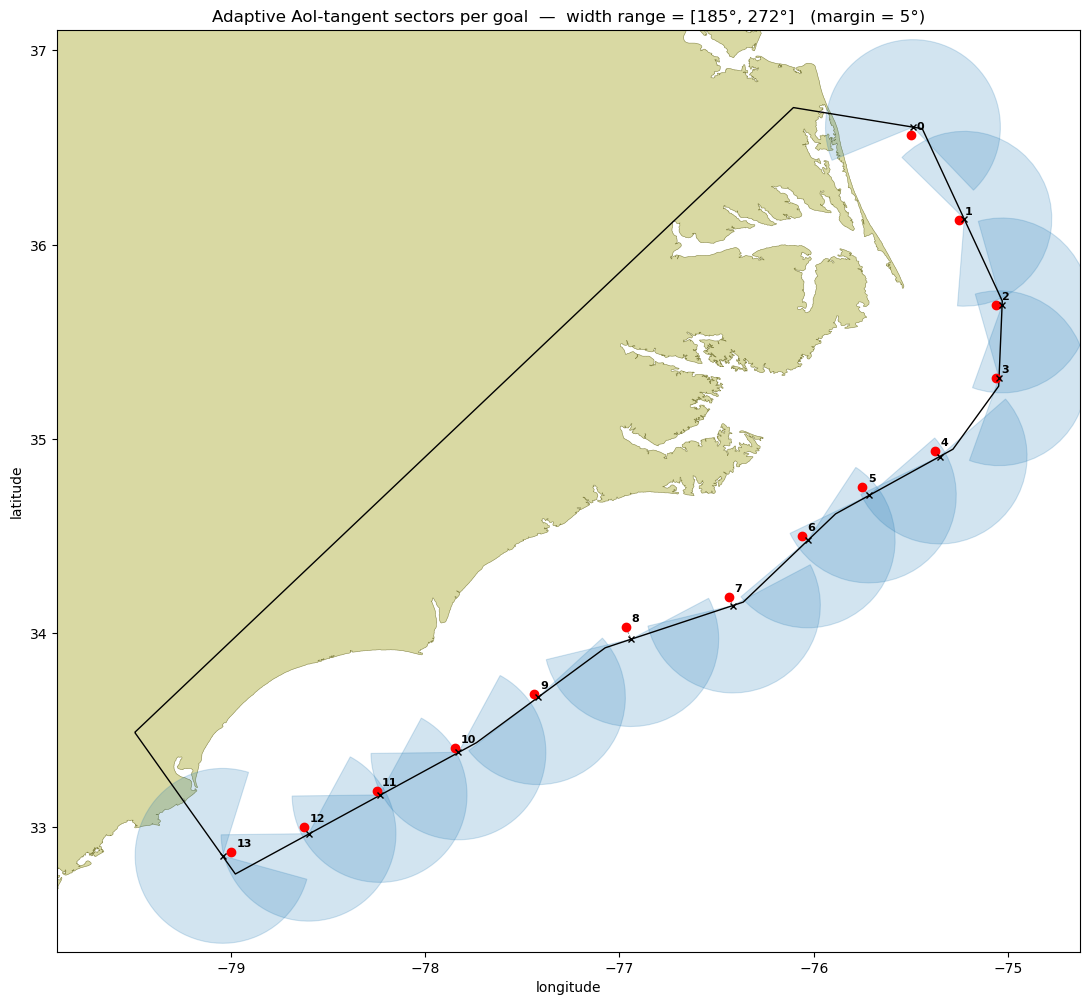

In [7]:
fig, ax = plt.subplots(figsize=(11, 11))

land_gdf.plot(ax=ax, color="#d9d9a3", edgecolor="#8a8a4a", lw=0.4)
aoi_gdf.boundary.plot(ax=ax, color="black", lw=1.0)

wedge_radius_deg = 0.45  # plot radius for the wedge (in degrees lat/lon)
for i, row in goals_gdf.iterrows():
    ax.plot(
        row.longitude, row.latitude, marker="o", color="red", markersize=6, zorder=5
    )
    ax.annotate(
        str(i),
        xy=(row.longitude, row.latitude),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8,
        fontweight="bold",
        zorder=6,
    )
    # Snapped boundary point + line from goal -> snap
    snap = snap_pts_gdf.iloc[i]
    ax.plot(
        [row.longitude, snap.x],
        [row.latitude, snap.y],
        color="gray",
        lw=0.6,
        ls="--",
        zorder=4,
    )
    ax.plot(snap.x, snap.y, marker="x", color="black", markersize=5, zorder=5)
    if not np.isnan(row.low_math):
        wedge = Wedge(
            (snap.x, snap.y),
            r=wedge_radius_deg,
            theta1=row.low_math,
            theta2=row.high_math,
            facecolor="#1f78b4",
            alpha=0.20,
            edgecolor="#1f78b4",
            lw=0.8,
        )
        ax.add_patch(wedge)

pad = 0.4
ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_aspect("equal")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
w_min = goals_gdf["width_deg"].min()
w_max = goals_gdf["width_deg"].max()
ax.set_title(
    "Adaptive AoI-tangent sectors per goal  —  "
    f"width range = [{w_min:.0f}°, {w_max:.0f}°]   (margin = {sector_margin_deg:g}°)"
)
plt.tight_layout()
plt.show()

## Save the enriched goals + a JSON snippet for `NorthCarolina.json`

In [9]:
goals_out_path.parent.mkdir(parents=True, exist_ok=True)
goals_gdf.to_file(goals_out_path, driver="GPKG", OVERWRITE=True)
print(
    f"wrote {len(goals_gdf)} goals (+ direction columns) to {goals_out_path.relative_to(CASE_DIR)}"
)

# JSON snippet for the `goals` section. Keys are 1-based strings to match the
# existing NorthCarolina.json layout.
snippet = {}
for i, row in goals_gdf.iterrows():
    snippet[str(i + 1)] = {
        "lat": float(row.latitude),
        "lon": float(row.longitude),
        "angles": [float(row.low_math), float(row.high_math)],
        "seapoint": int(row.seapoint) if "seapoint" in goals_gdf.columns else None,
    }

json_out_path.parent.mkdir(parents=True, exist_ok=True)
with json_out_path.open("w", encoding="utf-8") as f:
    json.dump({"goals": snippet}, f, indent=4)

print(f"wrote JSON snippet      to {json_out_path.relative_to(CASE_DIR)}")
print("\n--- snippet (paste into NorthCarolina.json) ---\n")
print(json.dumps({"goals": snippet}, indent=4))

wrote 14 goals (+ direction columns) to inputs/WHACS/NorthCarolina_whacs.gpkg
wrote JSON snippet      to outputs/goals_snippet.json

--- snippet (paste into NorthCarolina.json) ---

{
    "goals": {
        "1": {
            "lat": 36.5625,
            "lon": -75.5,
            "angles": [
                -46.2,
                202.3
            ],
            "seapoint": 1904482
        },
        "2": {
            "lat": 36.125,
            "lon": -75.25,
            "angles": [
                -94.5,
                135.5
            ],
            "seapoint": 1904397
        },
        "3": {
            "lat": 35.6875,
            "lon": -75.0625,
            "angles": [
                -109.8,
                105.8
            ],
            "seapoint": 1904324
        },
        "4": {
            "lat": 35.3125,
            "lon": -75.0625,
            "angles": [
                -109.8,
                105.8
            ],
            "seapoint": 1904228
        },
        "